## Project 2

## SEED = 560192899

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import erf
from scipy.integrate import quad

from mp2lib import (
    inv_cdf_exponential,
    inv_cdf_rayleigh,
    sample_by_inversion,
    ks_statistic,
    q_function
)

SEED = 560192899 #created on 11/02/2026
rng = np.random.default_rng(SEED)

rng_step1 = rng.spawn(1)[0]
rng_step2 = rng.spawn(1)[0]
rng_step3 = rng.spawn(1)[0]
rng_step4 = rng.spawn(1)[0]
rng_step5 = rng.spawn(1)[0]
rng_step6 = rng.spawn(1)[0]

N = 10**5
critical_value = 1.36 / np.sqrt(N)

print(f"95% KS critical value: {critical_value:.6f}")

95% KS critical value: 0.004301


## Step 1: From CDF to density

We generate $N=10^5$ independent samples of each distribution using NumPy's library generators and the Step 1 random stream. The parameters are $\lambda=1$ for the exponential and $\sigma=1$ for the Rayleigh.

### Uniform on $[0,1]$
The support is $[0,1]$.
$$
F_U(x)=\begin{cases}0,&x<0,\\x,&0\le x\le1,\\1,&x>1,\end{cases}
\qquad
f_U(x)=\begin{cases}1,&0\le x\le1,\\0,&\text{otherwise}.\end{cases}
$$

### Exponential with rate $\lambda=1$
The support is $[0,\infty)$.
$$
F_E(x)=\begin{cases}0,&x<0,\\1-e^{-x},&x\ge0,\end{cases}
\qquad
f_E(x)=\begin{cases}e^{-x},&x\ge0,\\0,&x<0.\end{cases}
$$

### Standard Gaussian
The support is $\mathbb R$.
$$
f_G(x)=\phi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2},
\qquad
F_G(x)=\Phi(x)=\int_{-\infty}^{x}\frac{1}{\sqrt{2\pi}}e^{-t^2/2}\,dt.
$$

### Rayleigh with scale $\sigma=1$
The support is $[0,\infty)$; $\sigma$ denotes the scale parameter.
$$
F_R(x)=\begin{cases}0,&x<0,\\1-e^{-x^2/2},&x\ge0,\end{cases}
\qquad
f_R(x)=\begin{cases}xe^{-x^2/2},&x\ge0,\\0,&x<0.\end{cases}
$$

### Closed-form summaries
For an exponential with rate $\lambda$,
$$
\mathbb E[E]=\frac1\lambda=1,\qquad
\operatorname{median}(E)=\frac{\ln2}{\lambda}\approx0.693147,\qquad
\operatorname{Var}(E)=\frac1{\lambda^2}=1.
$$
For a Rayleigh with scale $\sigma$,
$$
\mathbb E[R]=\sigma\sqrt{\frac\pi2}\approx1.253314,\qquad
\operatorname{median}(R)=\sigma\sqrt{2\ln2}\approx1.177410,\qquad
\operatorname{Var}(R)=\left(2-\frac\pi2\right)\sigma^2\approx0.429204.
$$

### Numerical goodness of fit
For sorted samples $x_{(1)},\ldots,x_{(N)}$, we evaluate both sides of each empirical CDF jump:
$$
D_N=\max_{1\le i\le N}\left\{\frac{i}{N}-F(x_{(i)}),\ F(x_{(i)})-\frac{i-1}{N}\right\}.
$$
We compare each statistic to the approximate 95% critical value $1.36/\sqrt{N}\approx0.004301$. A value below this cutoff means we do not reject the specified distribution at the 5% level; it does not prove an exact match. The histograms use `density=True` so that their total area is one.


In [2]:
def uniform_cdf(x):
    return np.where(x < 0, 0, np.where(x <= 1, x, 1))

def uniform_pdf(x):
    return np.where((x >= 0) & (x <= 1), 1, 0)

def exponential_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x), 0)

def exponential_pdf(x):
    return np.where(x >= 0, np.exp(-x), 0)

def gaussian_cdf(x):
    return stats.norm.cdf(x)

def gaussian_pdf(x):
    return stats.norm.pdf(x)

def rayleigh_cdf(x):
    return np.where(x >= 0, 1 - np.exp(-x**2 / 2), 0)

def rayleigh_pdf(x):
    return np.where(x >= 0, x * np.exp(-x**2 / 2), 0)

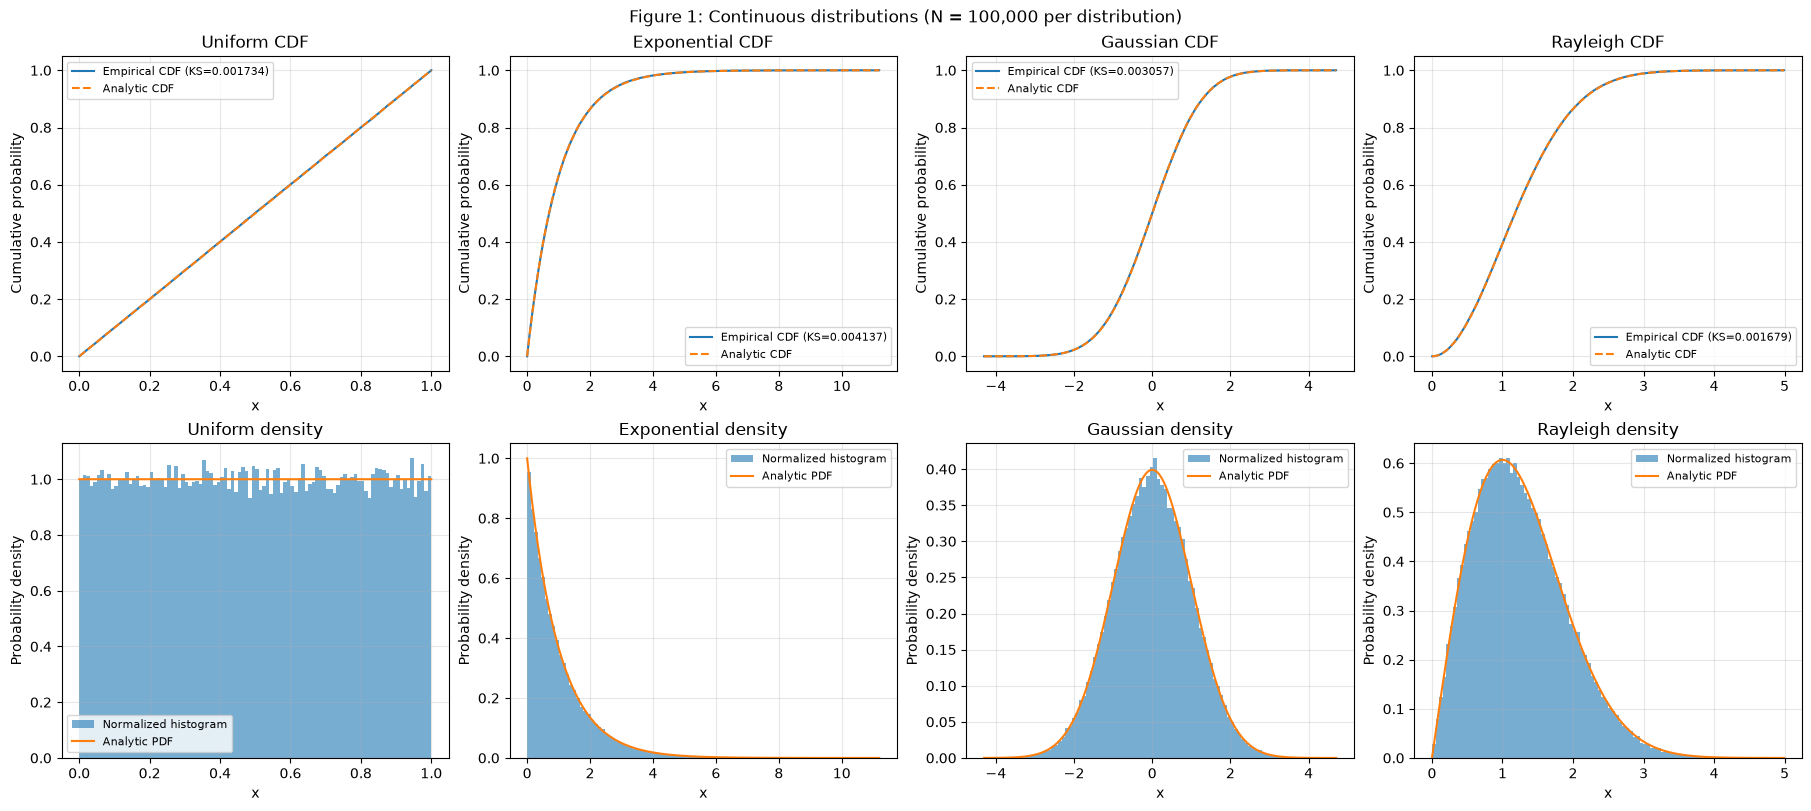

One-sample KS comparisons: N=100,000; 95% critical value=0.004301
Distribution    KS statistic  Critical value  Decision
Uniform             0.001734        0.004301  Do not reject
Exponential         0.004137        0.004301  Do not reject
Gaussian            0.003057        0.004301  Do not reject
Rayleigh            0.001679        0.004301  Do not reject

Sample summaries compared with exact closed forms (variance uses ddof=1):
Distribution   Quantity         Theory       Sample   Sample-theory
Exponential    Mean           1.000000     1.000990        0.000990
Exponential    Median         0.693147     0.700861        0.007714
Exponential    Variance       1.000000     0.991246       -0.008754
Rayleigh       Mean           1.253314     1.252295       -0.001019
Rayleigh       Median         1.177410     1.177535        0.000125
Rayleigh       Variance       0.429204     0.428423       -0.000781


In [3]:
uniform_samples = rng_step1.random(N)
exponential_samples = rng_step1.exponential(scale=1, size=N)
gaussian_samples = rng_step1.normal(0, 1, N)
rayleigh_samples = rng_step1.rayleigh(scale=1, size=N)

distributions = [
    ("Uniform", uniform_samples, uniform_cdf, uniform_pdf),
    ("Exponential", exponential_samples, exponential_cdf, exponential_pdf),
    ("Gaussian", gaussian_samples, gaussian_cdf, gaussian_pdf),
    ("Rayleigh", rayleigh_samples, rayleigh_cdf, rayleigh_pdf)
]

step1_ks = {name: ks_statistic(samples, cdf)
            for name, samples, cdf, pdf in distributions}
fig, axes = plt.subplots(2, 4, figsize=(18, 8), constrained_layout=True)
fig.suptitle(f"Figure 1: Continuous distributions (N = {N:,} per distribution)")

for col, (name, samples, cdf, pdf) in enumerate(distributions):
    ordered = np.sort(samples)
    empirical = np.arange(1, N + 1) / N
    x = np.linspace(min(0, ordered.min()), ordered.max(), 1200)
    axes[0, col].step(ordered, empirical, where="post",
                      label=f"Empirical CDF (KS={step1_ks[name]:.6f})")
    axes[0, col].plot(x, cdf(x), "--", label="Analytic CDF")
    axes[0, col].set(title=name + " CDF", xlabel="x", ylabel="Cumulative probability")
    axes[1, col].hist(samples, bins=100, density=True, alpha=0.6,
                      label="Normalized histogram")
    axes[1, col].plot(x, pdf(x), label="Analytic PDF")
    axes[1, col].set(title=name + " density", xlabel="x", ylabel="Probability density")
    for ax in axes[:, col]:
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)

plt.show()

print(f"One-sample KS comparisons: N={N:,}; 95% critical value={critical_value:.6f}")
print(f"{'Distribution':<14} {'KS statistic':>13} {'Critical value':>15}  Decision")
for name, statistic in step1_ks.items():
    decision = "Do not reject" if statistic <= critical_value else "Reject at 5%"
    print(f"{name:<14} {statistic:13.6f} {critical_value:15.6f}  {decision}")

print("\nSample summaries compared with exact closed forms (variance uses ddof=1):")
print(f"{'Distribution':<14} {'Quantity':<10} {'Theory':>12} {'Sample':>12} {'Sample-theory':>15}")
for name, samples, theoretical in [
    ("Exponential", exponential_samples, (1.0, np.log(2), 1.0)),
    ("Rayleigh", rayleigh_samples,
     (np.sqrt(np.pi / 2), np.sqrt(2 * np.log(2)), 2 - np.pi / 2))
]:
    observed = (np.mean(samples), np.median(samples), np.var(samples, ddof=1))
    for quantity, theory, sample in zip(("Mean", "Median", "Variance"), theoretical, observed):
        print(f"{name:<14} {quantity:<10} {theory:12.6f} {sample:12.6f} {sample-theory:15.6f}")


### Interpretation of Figure 1

All four KS statistics are below the 95% critical value $0.004301$: uniform $0.001734$, exponential $0.004137$, Gaussian $0.003057$, and Rayleigh $0.001679$. Thus none of the four specified distributions is rejected by its individual 5% KS test; the exponential statistic is closest to the cutoff. These numerical comparisons support the visual agreement in Figure 1.

The exponential sample mean, median, and unbiased variance are approximately $1.000990$, $0.700861$, and $0.991246$, compared with theoretical values $1$, $0.693147$, and $1$. The Rayleigh values are approximately $1.252295$, $1.177535$, and $0.428423$, compared with $1.253314$, $1.177410$, and $0.429204$; the printed table quantifies every difference.

The exponential density is right-skewed, so its long positive tail pulls the mean above the median, with theoretical ratio $1/\ln2\approx1.443$. The Gaussian density is symmetric about zero, so its mean and median coincide at zero.


## Step 2: Build your own generator by inversion

### Inversion result
Let $U\sim\operatorname{Uniform}(0,1)$ and let $F$ be a continuous CDF that is strictly increasing on its support. Define $Y=F^{-1}(U)$. For $y$ in the support, monotonicity gives
$$
\Pr(Y\le y)=\Pr(F^{-1}(U)\le y)=\Pr(U\le F(y))=F(y).
$$
Outside the support, both sides equal zero or one as appropriate, so $Y$ has CDF $F$.

### Exponential inverse CDF
For rate $\lambda>0$ and $x\ge0$,
$$
u=1-e^{-\lambda x}
\ \Longrightarrow\ 1-u=e^{-\lambda x}
\ \Longrightarrow\ \ln(1-u)=-\lambda x
\ \Longrightarrow\ F_E^{-1}(u)=-\frac{\ln(1-u)}{\lambda}.
$$

### Rayleigh inverse CDF
For scale $\sigma>0$ and $x\ge0$,
$$
u=1-e^{-x^2/(2\sigma^2)}
\ \Longrightarrow\ 1-u=e^{-x^2/(2\sigma^2)}
\ \Longrightarrow\ \ln(1-u)=-\frac{x^2}{2\sigma^2}
$$
$$
\Longrightarrow\ x^2=-2\sigma^2\ln(1-u)
\ \Longrightarrow\ F_R^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}.
$$
We take the nonnegative square root because the Rayleigh support is $[0,\infty)$.

### Implementation and endpoints
`sample_by_inversion` draws uniforms using only `rng_step2.random()` and passes them to our inverse-CDF functions in `mp2lib.py`. Both functions evaluate $\ln(1-u)$ with `np.log1p(-u)`, which avoids subtracting a tiny $u$ from one and losing precision. Since `rng.random()` returns $0\le u<1$, $u=0$ safely maps to zero in both inverses and $u=1$ is never drawn; the functions reject inputs outside this interval. No clipping, discarded samples, or additional random draws are needed.

Because $U$ and $1-U$ have the same continuous uniform distribution, both $-\ln(U)/\lambda$ and $-\ln(1-U)/\lambda$ have the exponential distribution; we use the latter to handle a generated zero safely.

### Verification plan
Generate $10^5$ inversion samples of each distribution. Compare each sample with its analytic CDF using our one-sample KS statistic and the 95% cutoff $1.36/\sqrt{N}$. Reuse the independent library-generated samples from Step 1 for a direct two-sample KS comparison, whose approximate 95% cutoff is $1.36\sqrt{1/N+1/N}$; this comparison does not call the exponential or Rayleigh library generators again in Step 2.


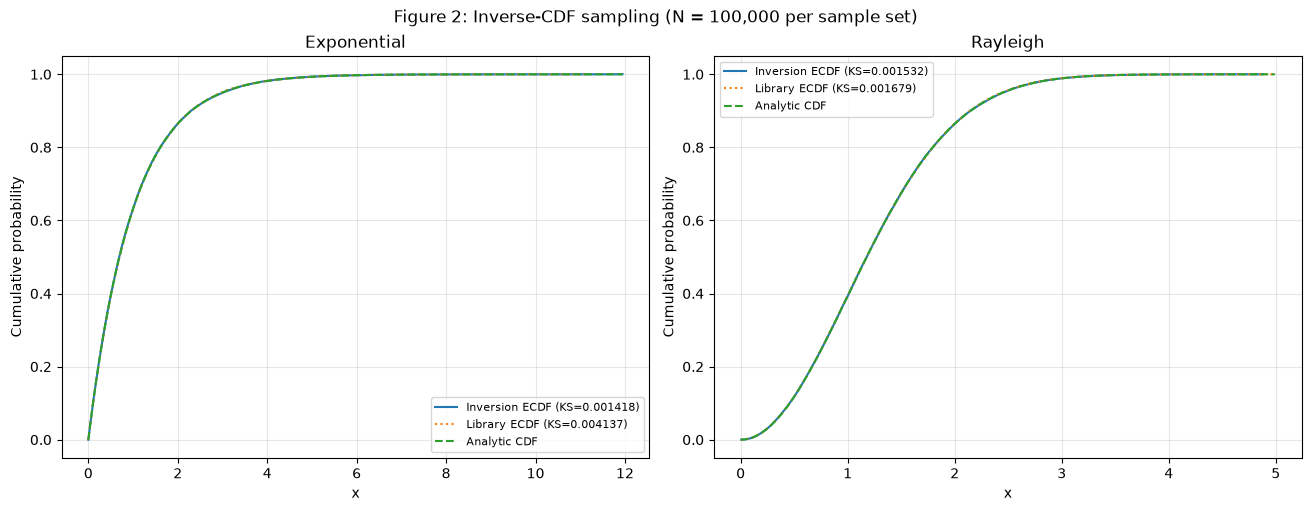

N = 100,000 per sample set
One-sample 95% KS cutoff: 0.004301
Two-sample 95% KS cutoff: 0.006082
Distribution    Inversion/theory   Library/theory   Inversion/library
Exponential             0.001418         0.004137            0.005120
  Inversion vs theory: do not reject
  Inversion vs library: do not reject
Rayleigh                0.001532         0.001679            0.002530
  Inversion vs theory: do not reject
  Inversion vs library: do not reject

Endpoint and numerical stability checks:
Exponential: inverse(0)=0.0; all tested values finite=True
Rayleigh: inverse(0)=0.0; all tested values finite=True


In [4]:
inversion_exponential = sample_by_inversion(
    inv_cdf_exponential, N, rng_step2, lam=1
)
inversion_rayleigh = sample_by_inversion(
    inv_cdf_rayleigh, N, rng_step2, sigma=1
)

exp_ks = ks_statistic(inversion_exponential, exponential_cdf)
rayleigh_ks = ks_statistic(inversion_rayleigh, rayleigh_cdf)
two_sample_critical = 1.36 * np.sqrt(2 / N)
step2_results = []

for name, inverted, library, cdf in [
    ("Exponential", inversion_exponential, exponential_samples, exponential_cdf),
    ("Rayleigh", inversion_rayleigh, rayleigh_samples, rayleigh_cdf)
]:
    step2_results.append({
        "name": name,
        "inversion_ks": ks_statistic(inverted, cdf),
        "library_ks": ks_statistic(library, cdf),
        "two_sample_ks": stats.ks_2samp(inverted, library).statistic
    })

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle(f"Figure 2: Inverse-CDF sampling (N = {N:,} per sample set)")
for ax, row, inverted, library, cdf in zip(
    axes, step2_results,
    (inversion_exponential, inversion_rayleigh),
    (exponential_samples, rayleigh_samples),
    (exponential_cdf, rayleigh_cdf)
):
    empirical = np.arange(1, N + 1) / N
    ax.step(np.sort(inverted), empirical, where="post",
            label=f"Inversion ECDF (KS={row['inversion_ks']:.6f})")
    ax.step(np.sort(library), empirical, where="post", linestyle=":",
            label=f"Library ECDF (KS={row['library_ks']:.6f})")
    x = np.linspace(0, max(inverted.max(), library.max()), 1200)
    ax.plot(x, cdf(x), "--", label="Analytic CDF")
    ax.set(title=row["name"], xlabel="x", ylabel="Cumulative probability")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.show()

print(f"N = {N:,} per sample set")
print(f"One-sample 95% KS cutoff: {critical_value:.6f}")
print(f"Two-sample 95% KS cutoff: {two_sample_critical:.6f}")
print(f"{'Distribution':<14} {'Inversion/theory':>17} {'Library/theory':>16} {'Inversion/library':>19}")
for row in step2_results:
    print(f"{row['name']:<14} {row['inversion_ks']:17.6f} "
          f"{row['library_ks']:16.6f} {row['two_sample_ks']:19.6f}")
    one_sample_ok = row['inversion_ks'] <= critical_value
    two_sample_ok = row['two_sample_ks'] <= two_sample_critical
    print("  Inversion vs theory:", "do not reject" if one_sample_ok else "reject at 5%")
    print("  Inversion vs library:", "do not reject" if two_sample_ok else "reject at 5%")

print("\nEndpoint and numerical stability checks:")
u_check = np.array([0.0, np.nextafter(0.0, 1.0), np.nextafter(1.0, 0.0)])
for name, values in [
    ("Exponential", inv_cdf_exponential(u_check, lam=1)),
    ("Rayleigh", inv_cdf_rayleigh(u_check, sigma=1))
]:
    print(f"{name}: inverse(0)={values[0]:.1f}; "
          f"all tested values finite={np.all(np.isfinite(values))}")


### Interpretation of Figure 2

The inversion samples give one-sample KS statistics of $0.001418$ for the exponential and $0.001532$ for the Rayleigh, both below the 95% cutoff $0.004301$. Neither specified distribution is rejected by its individual test. The Step 1 library samples give statistics of $0.004137$ and $0.001679$ against those same analytic CDFs.

The direct inversion-versus-library two-sample KS statistics are $0.005120$ and $0.002530$, below their separate 95% cutoff $0.006082$. These comparisons provide numerical evidence that both sampling methods produce the intended distributions, while allowing the two independent sample sets to differ. The endpoint checks also confirm that a uniform value of zero produces zero and that inputs just below one produce finite samples.


## Step 3: A function of a random variable

Let $X\sim\mathcal N(0,1)$ and $Y=X^2$. The support of $Y$ is $[0,\infty)$.

### Deriving the CDF
For $y>0$,
$$
X^2\le y\ \Longleftrightarrow\ -\sqrt y\le X\le\sqrt y.
$$
Using $\Phi(-a)=1-\Phi(a)$,
$$
F_Y(y)=\Pr(-\sqrt y\le X\le\sqrt y)
=\Phi(\sqrt y)-\Phi(-\sqrt y)=2\Phi(\sqrt y)-1.
$$
Thus
$$
F_Y(y)=\begin{cases}0,&y\le0,\\2\Phi(\sqrt y)-1,&y>0.\end{cases}
$$

### Differentiating to obtain the density
Since $\Phi'(x)=\phi(x)$, the chain rule gives, for $y>0$,
$$
f_Y(y)=\frac{d}{dy}\big[2\Phi(\sqrt y)-1\big]
=2\phi(\sqrt y)\frac{1}{2\sqrt y}
=\frac{\phi(\sqrt y)}{\sqrt y}
=\frac{e^{-y/2}}{\sqrt{2\pi y}}.
$$
The density is zero for $y<0$ and diverges as $y\to0^+$; there is no point mass at zero. This is the chi-square density with one degree of freedom.

### Why an infinite density can integrate to one
The squaring map is flat at the origin: its derivative $2x$ vanishes there. It maps the slab $[-\sqrt\varepsilon,\sqrt\varepsilon]$ into $[0,\varepsilon]$, so
$$
\Pr(Y\le\varepsilon)=2\Phi(\sqrt\varepsilon)-1
\sim\sqrt{\frac2\pi}\sqrt\varepsilon.
$$
Dividing this probability by the interval width $\varepsilon$ gives an average density proportional to $\varepsilon^{-1/2}$, which grows without bound even though the interval probability tends to zero. In particular,
$$
\int_0^\varepsilon\frac{dy}{\sqrt{2\pi y}}
=\sqrt{\frac2\pi}\sqrt\varepsilon<\infty.
$$
For the full density, substitute $y=x^2$, $dy=2x\,dx$ with $x\ge0$:
$$
\int_0^\infty\frac{e^{-y/2}}{\sqrt{2\pi y}}\,dy
=2\int_0^\infty\frac{e^{-x^2/2}}{\sqrt{2\pi}}\,dx=1.
$$
We also confirm the improper integral numerically below.

### Probabilities, median, and moments
$$
\Pr(Y\le1)=2\Phi(1)-1\approx0.682689,
\qquad
\Pr(Y\le0.1)=2\Phi(\sqrt{0.1})-1\approx0.248170.
$$
The median $m$ satisfies
$$
2\Phi(\sqrt m)-1=\tfrac12
\ \Longrightarrow\ \Phi(\sqrt m)=\tfrac34
\ \Longrightarrow\ m=[\Phi^{-1}(3/4)]^2\approx0.454936.
$$
Since $\mathbb E[X]=0$ and $\operatorname{Var}(X)=1$,
$$
\mathbb E[Y]=\mathbb E[X^2]=\operatorname{Var}(X)+(\mathbb E[X])^2=1.
$$
Using $\phi'(x)=-x\phi(x)$ and integration by parts,
$$
\mathbb E[X^4]=\int_{-\infty}^{\infty}x^3[x\phi(x)]\,dx
=\left[-x^3\phi(x)\right]_{-\infty}^{\infty}
+3\int_{-\infty}^{\infty}x^2\phi(x)\,dx=0+3=3.
$$
Therefore
$$
\operatorname{Var}(Y)=\mathbb E[X^4]-(\mathbb E[X^2])^2=3-1=2.
$$

### Simulation and binning
Use $M=10^6$ samples from the Step 3 generator. For each estimated probability $\widehat p$, report the trial count and estimated binomial standard error $\sqrt{\widehat p(1-\widehat p)/M}$. A KS comparison against the derived CDF provides a numerical goodness-of-fit check.

Figure 3 uses log-spaced bin edges starting at $10^{-4}$, plus an initial bin from zero to $10^{-4}$ and a final edge beyond the largest observation. All samples are included in the normalized histogram, so no tail is discarded and renormalized. Both panels use the same bins; the linear panel zooms near the origin, and the log-log panel shows the wider distribution. A finite histogram bar measures an average density across its bin, so it cannot itself become infinite.

Near zero,
$$
f_Y(y)\sim(2\pi)^{-1/2}y^{-1/2},\qquad
\log f_Y(y)=-\tfrac12\log(2\pi)-\tfrac12\log y-\tfrac y2.
$$
Consequently the log-log slope tends to $-1/2$ as $y\to0^+$; it is not constant in the tail because of $e^{-y/2}$.


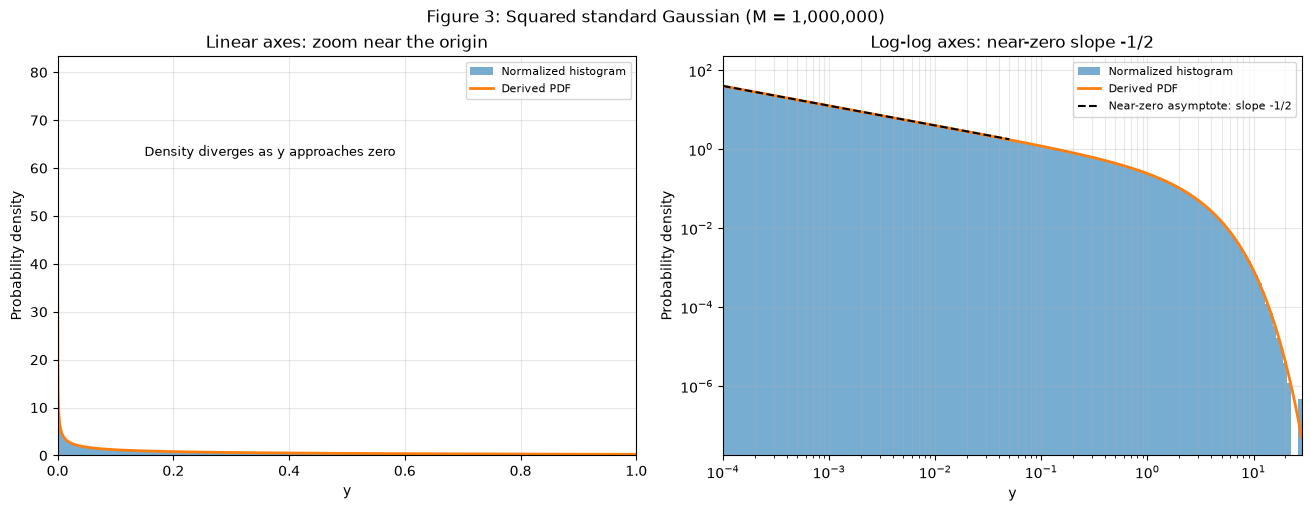

Integral of derived PDF = 1.000000000001
Quadrature estimated absolute error = 2.011e-11
KS statistic = 0.000756; 95% critical value = 0.001360; M = 1,000,000
KS decision: do not reject

Monte Carlo probabilities (one standard error):
Event                 Theory    Empirical       Trials           SE
Y <= 1.0            0.682689     0.682793    1,000,000     0.000465
Y <= 0.1            0.248170     0.248308    1,000,000     0.000432

Summary comparisons (sample variance uses ddof=1):
Quantity           Theory    Empirical   Difference
Median           0.454936     0.456369     0.001432
Mean             1.000000     0.999182    -0.000818
Variance         2.000000     1.990649    -0.009351
Near-zero theoretical log-log slope = -0.5.


In [5]:
def squared_gaussian_cdf(y):
    y = np.asarray(y, dtype=float)
    # Clamp before taking the square root to avoid warnings for negative inputs.
    return erf(np.sqrt(np.maximum(y, 0.0) / 2))

def squared_gaussian_pdf(y):
    y = np.asarray(y, dtype=float)
    result = np.zeros_like(y)
    positive = y > 0
    result[positive] = np.exp(-y[positive] / 2) / np.sqrt(2 * np.pi * y[positive])
    # Explicitly represent the right-hand divergence at the origin.
    return np.where(y == 0, np.inf, result)

integral, integration_error = quad(
    lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi * y),
    0, np.inf, epsabs=1e-10, epsrel=1e-10
)
M = 10**6
y_samples = rng_step3.normal(0, 1, M)**2
y_ks = ks_statistic(y_samples, squared_gaussian_cdf)
y_ks_critical = 1.36 / np.sqrt(M)

bins = np.concatenate(([0.0], np.geomspace(
    1e-4, np.nextafter(y_samples.max(), np.inf), 160
)))
y_plot = np.geomspace(1e-4, bins[-1], 1500)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle(f"Figure 3: Squared standard Gaussian (M = {M:,})")
for ax in axes:
    ax.hist(y_samples, bins=bins, density=True, alpha=0.6,
            label="Normalized histogram")
    ax.plot(y_plot, squared_gaussian_pdf(y_plot), linewidth=2,
            label="Derived PDF")
    ax.set(xlabel="y", ylabel="Probability density")
    ax.grid(True, which="both", alpha=0.3)
axes[0].set(title="Linear axes: zoom near the origin", xlim=(0, 1))
axes[0].text(0.15, 0.75, "Density diverges as y approaches zero",
             transform=axes[0].transAxes, fontsize=9)
axes[1].set(xscale="log", yscale="log", title="Log-log axes: near-zero slope -1/2",
            xlim=(1e-4, bins[-1]))
near_zero = np.geomspace(1e-4, 0.05, 150)
axes[1].plot(near_zero, 1 / np.sqrt(2 * np.pi * near_zero), "k--",
             label="Near-zero asymptote: slope -1/2")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

print(f"Integral of derived PDF = {integral:.12f}")
print(f"Quadrature estimated absolute error = {integration_error:.3e}")
print(f"KS statistic = {y_ks:.6f}; 95% critical value = {y_ks_critical:.6f}; M = {M:,}")
print("KS decision:", "do not reject" if y_ks <= y_ks_critical else "reject at 5%")

step3_probabilities = []
print("\nMonte Carlo probabilities (one standard error):")
print(f"{'Event':<15} {'Theory':>12} {'Empirical':>12} {'Trials':>12} {'SE':>12}")
for cutoff in (1.0, 0.1):
    theory = float(squared_gaussian_cdf(cutoff))
    empirical = np.mean(y_samples <= cutoff)
    se = np.sqrt(empirical * (1 - empirical) / M)
    step3_probabilities.append((cutoff, theory, empirical, se))
    print(f"{'Y <= ' + str(cutoff):<15} {theory:12.6f} {empirical:12.6f} {M:12,d} {se:12.6f}")

step3_summaries = [
    ("Median", stats.norm.ppf(0.75)**2, np.median(y_samples)),
    ("Mean", 1.0, np.mean(y_samples)),
    ("Variance", 2.0, np.var(y_samples, ddof=1))
]
print("\nSummary comparisons (sample variance uses ddof=1):")
print(f"{'Quantity':<12} {'Theory':>12} {'Empirical':>12} {'Difference':>12}")
for name, theory, empirical in step3_summaries:
    print(f"{name:<12} {theory:12.6f} {empirical:12.6f} {empirical-theory:12.6f}")
print("Near-zero theoretical log-log slope = -0.5.")


### Interpretation of Figure 3

The linear panel shows probability concentrated near the origin, while the log-log panel reveals the approximately straight segment with slope $-1/2$ at small $y$. This comes from the factor $y^{-1/2}$ in the derived density. The curve bends downward at larger $y$ because the exponential factor becomes significant. The numerical integral is $1.000000000001$, confirming normalization despite the integrable singularity.

The one-sample KS statistic is $0.000756$, below the 95% critical value $0.001360$ at $M=10^6$, so the derived CDF is not rejected by this test. The estimated probabilities are $\widehat{\Pr}(Y\le1)=0.682793$ with standard error $0.000465$, and $\widehat{\Pr}(Y\le0.1)=0.248308$ with standard error $0.000432$; both use $10^6$ trials and are within one estimated standard error of their analytic values $0.682689$ and $0.248170$.

The empirical median is $0.456369$, mean $0.999182$, and unbiased variance $1.990649$, compared with theoretical values $0.454936$, $1$, and $2$. The median is well below the mean: much of the probability lies near zero, while the right tail pulls the mean upward. A divergent density at zero does not imply a point mass there; the probability of an interval shrinking to zero still tends to zero.


## Step 4: Expectation and moments

### Rayleigh raw moments
For a Rayleigh random variable with scale 1,
$$
E[R^k]=\int_0^\infty r^{k+1}e^{-r^2/2}\,dr.
$$
Substitute $t=r^2/2$, so $r\,dr=dt$:
$$
E[R^k]=2^{k/2}\int_0^\infty t^{k/2}e^{-t}\,dt
=2^{k/2}\Gamma(1+k/2).
$$
Thus the first four raw moments are
$$
E[R]=\sqrt{\pi/2}\approx1.253314,\quad E[R^2]=2,
$$
$$
E[R^3]=3\sqrt{\pi/2}\approx3.759942,\quad E[R^4]=8.
$$
For $M$ independent samples, $\widehat m_k=M^{-1}\sum_i R_i^k$ has standard error
$$
SE_k=\sqrt{\frac{E[R^{2k}]-(E[R^k])^2}{M}}.
$$
We compute these standard errors from the exact moments and report the signed differences $z_k=(\widehat m_k-E[R^k])/SE_k$.

### Pareto moments
For shape $1.5$ and scale $1$, the density is $f_P(x)=1.5x^{-2.5}$ for $x\ge1$ and zero otherwise. Its $k$th raw moment is
$$
E[P^k]=1.5\int_1^\infty x^{k-2.5}\,dx.
$$
The integral converges only when $k-2.5<-1$, or $k<1.5$. In that case,
$$
E[P^k]=1.5\left[\frac{x^{k-1.5}}{k-1.5}\right]_1^\infty
=\frac{1.5}{1.5-k}.
$$
Therefore $E[P]=1.5/(1.5-1)=3$, but
$$
E[P^2]=1.5\int_1^\infty x^{-1/2}\,dx
=\lim_{b\to\infty}3(\sqrt b-1)=\infty.
$$
The mean exists, but the variance is infinite.

### Running estimates
We generate one sequence of $10^6$ samples per distribution and examine nested prefixes, rather than generating new data for each sample size. The running mean and unbiased sample variance are
$$
\bar x_n=\frac1n\sum_{i=1}^n x_i,\qquad
s_n^2=\frac{\sum_{i=1}^n x_i^2-n\bar x_n^2}{n-1}.
$$
For the Rayleigh, the population mean and variance are $\sqrt{\pi/2}$ and $2-\pi/2$. For the Pareto, the population mean is 3 and there is no finite population variance to draw.


Rayleigh raw moments: M = 1,000,000
  k       Theory     Estimate           SE   Difference/SE
  1     1.253314     1.253534     0.000655           0.335
  2     2.000000     2.000955     0.002000           0.477
  3     3.759942     3.764051     0.005819           0.706
  4     8.000000     8.016427     0.017889           0.918

Running estimates from nested sample prefixes:
Distribution            N     Sample mean    Sample variance
Rayleigh            1,000        1.255712           0.394573
Rayleigh           10,000        1.250372           0.424182
Rayleigh          100,000        1.250819           0.426238
Rayleigh        1,000,000        1.253534           0.429608
Pareto              1,000        3.097552          55.336838
Pareto             10,000        3.003130         110.622197
Pareto            100,000        2.947463         189.206537
Pareto          1,000,000        2.982517        1133.992227


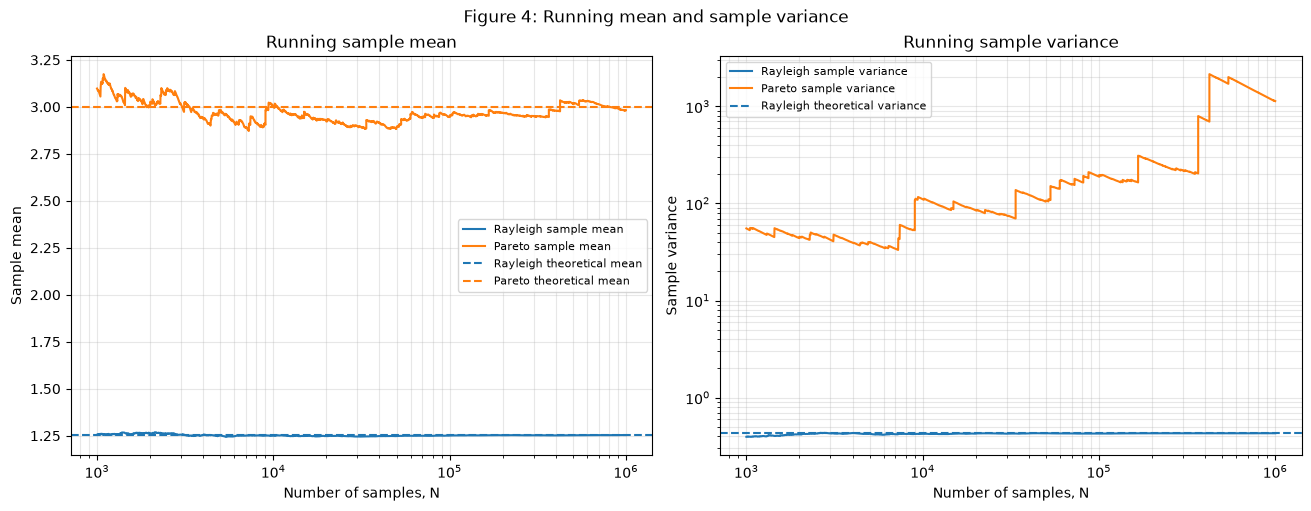

In [6]:
from math import gamma

M4 = 10**6
rayleigh_step4 = rng_step4.rayleigh(scale=1, size=M4)
# NumPy returns a Lomax variate; +1 gives Pareto support [1, infinity).
pareto_step4 = rng_step4.pareto(a=1.5, size=M4) + 1.0

def rayleigh_raw_moment(k):
    return 2.0**(k / 2) * gamma(1 + k / 2)

step4_moments = []
print(f"Rayleigh raw moments: M = {M4:,}")
print(f"{'k':>3} {'Theory':>12} {'Estimate':>12} {'SE':>12} {'Difference/SE':>15}")
for k in range(1, 5):
    theory = rayleigh_raw_moment(k)
    estimate = np.mean(rayleigh_step4**k)
    se = np.sqrt((rayleigh_raw_moment(2*k) - theory**2) / M4)
    z = (estimate - theory) / se
    step4_moments.append((k, theory, estimate, se, z))
    print(f"{k:3d} {theory:12.6f} {estimate:12.6f} {se:12.6f} {z:15.3f}")

def running_summaries(samples):
    n = np.arange(1, samples.size + 1)
    sums = np.cumsum(samples)
    squared_sums = np.cumsum(samples**2)
    means = sums / n
    variances = np.full(samples.size, np.nan)
    variances[1:] = (squared_sums[1:] - sums[1:]**2 / n[1:]) / (n[1:] - 1)
    return means, variances

rayleigh_mean4, rayleigh_var4 = running_summaries(rayleigh_step4)
pareto_mean4, pareto_var4 = running_summaries(pareto_step4)
checkpoints4 = np.array([10**3, 10**4, 10**5, 10**6])

print("\nRunning estimates from nested sample prefixes:")
print(f"{'Distribution':<14} {'N':>10} {'Sample mean':>15} {'Sample variance':>18}")
for name, means, variances in [
    ("Rayleigh", rayleigh_mean4, rayleigh_var4),
    ("Pareto", pareto_mean4, pareto_var4)
]:
    for n in checkpoints4:
        print(f"{name:<14} {n:10,d} {means[n-1]:15.6f} {variances[n-1]:18.6f}")

# Include large Pareto observations and their preceding points so jumps
# remain visible while keeping the figure small and fast to render.
large_indices = np.argpartition(pareto_step4, -100)[-100:]
plot_n4 = np.unique(np.concatenate((
    np.geomspace(10**3, M4, 2500).astype(int), checkpoints4,
    large_indices, large_indices + 1
)))
plot_n4 = plot_n4[(plot_n4 >= 10**3) & (plot_n4 <= M4)]
idx4 = plot_n4 - 1
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
fig.suptitle("Figure 4: Running mean and sample variance")
axes[0].plot(plot_n4, rayleigh_mean4[idx4], label="Rayleigh sample mean")
axes[0].plot(plot_n4, pareto_mean4[idx4], label="Pareto sample mean")
axes[0].axhline(np.sqrt(np.pi/2), color="C0", linestyle="--",
                label="Rayleigh theoretical mean")
axes[0].axhline(3, color="C1", linestyle="--", label="Pareto theoretical mean")
axes[0].set(title="Running sample mean", xlabel="Number of samples, N",
            ylabel="Sample mean", xscale="log")
axes[1].plot(plot_n4, rayleigh_var4[idx4], label="Rayleigh sample variance")
axes[1].plot(plot_n4, pareto_var4[idx4], label="Pareto sample variance")
axes[1].axhline(2-np.pi/2, color="C0", linestyle="--",
                label="Rayleigh theoretical variance")
axes[1].set(title="Running sample variance", xlabel="Number of samples, N",
            ylabel="Sample variance", xscale="log", yscale="log")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(True, which="both", alpha=0.3)
plt.show()


### Interpretation of Figure 4

The four Rayleigh moment estimates differ from theory by $0.335$, $0.477$, $0.706$, and $0.918$ standard errors, respectively. The running Rayleigh mean and variance approach their finite population values, approximately $1.253314$ and $0.429204$.

For the Pareto, the sample means at $N=10^3,10^4,10^5,10^6$ are $3.097552$, $3.003130$, $2.947463$, and $2.982517$, respectively. The corresponding sample variances are $55.336838$, $110.622197$, $189.206537$, and $1133.992227$. The population mean exists, so the sample mean converges to 3 in the long run, although rare large observations cause jumps and convergence need not be monotonic. The variance has no finite population value to approach; the jumps in the plot occur when large observations enter the sample. Temporary stability, or a decrease between selected checkpoints, does not demonstrate convergence to a finite variance.

The code prints a finite sample variance because a finite simulated sample contains only finite observations. That number describes the spread of the observed sample; it does not establish that the population has a finite variance.

Before reporting an error bar based on a sample standard deviation, check that a finite population variance is a reasonable assumption. For this Pareto distribution, the usual $s/\sqrt N$ standard error and finite-variance Gaussian confidence interval for the sample mean are not justified. The variance panel uses a logarithmic vertical axis to keep the Rayleigh and Pareto estimates visible together; both panels use a logarithmic horizontal axis.


## Step 5: The central limit theorem, and where it fails

### Uniform sums: theoretical standardization
Let $U_i$ be independent uniform random variables on $[0,1]$, and $S_N=\sum_{i=1}^N U_i$. Since $E[U_i]=1/2$ and $\operatorname{Var}(U_i)=1/12$, independence gives
$$
E[S_N]=\frac N2,\qquad \operatorname{Var}(S_N)=\frac N{12}.
$$
We standardize with the exact population quantities:
$$
Z_N=\frac{S_N-N/2}{\sqrt{N/12}}.
$$
Each $Z_N$ has mean zero and variance one. The classical CLT implies $Z_N\Rightarrow\mathcal N(0,1)$ as $N\to\infty$. For each $N=1,2,3,5,10,30$, generate $L=200{,}000$ independent sums and compute the one-sample KS statistic against $\Phi$. The approximate 95% cutoff is $1.36/\sqrt L\approx0.003041$.

### Pareto sums: what can be standardized?
For independent Pareto summands of shape $\alpha=1.5$ and scale 1, the mean is 3 but the variance is infinite, as shown in Step 4. Thus $S_N$ has mean $3N$, but no finite population standard deviation: the uniform experiment's population standardization cannot be repeated literally.

For a descriptive shape comparison at $N=1,10,100,1000$, generate $L=200{,}000$ independent sums and compute
$$
\widetilde Z_{N,j}=\frac{S_{N,j}-\overline S_N}{s_{S_N}},
$$
where $\overline S_N$ and $s_{S_N}$ are the empirical mean and sample standard deviation across the $L$ simulated sums. These values have empirical mean zero and sample variance one, but this does not give the population a finite variance. Because these centering and scaling parameters are fitted from the same data, the ordinary fixed-CDF KS cutoff is only a reference for this Pareto curve, not a calibrated 5% normality test.

The violated classical CLT hypothesis is finite summand variance. Under the generalized CLT, the properly centered and scaled sums
$$
\frac{S_N-3N}{N^{1/\alpha}}=\frac{S_N-3N}{N^{2/3}}
$$
converge to a non-Gaussian, right-skewed $\alpha$-stable law with $\alpha=1.5$ (with its scale set by the tail constant). This statement concerns deterministic stable-law scaling, not the empirical standardization above. We also print KS distances for these deterministically scaled sums to show that changing the normalization does not create Gaussian convergence.

Reference for the stable CLT: [Chen, Nourdin, and Xu, *Stein's method for asymmetric alpha-stable distributions, with application to the stable CLT*](https://arxiv.org/abs/1808.02405).

The simulation uses vectorized batches to bound memory use; the loops operate over batches and experiment settings, not over individual trials.


Independent sums per setting: L = 200,000
Fixed-CDF 95% KS cutoff = 0.003041

Uniform sums, using exact population centering and scaling:
     N    KS vs normal  Decision
     1        0.058846  Reject at 5%
     2        0.017140  Reject at 5%
     3        0.010686  Reject at 5%
     5        0.007370  Reject at 5%
    10        0.003502  Reject at 5%
    30        0.001958  Do not reject

Pareto sums (empirical standardization is descriptive):
     N    Empirical mean      Empirical SD    KS: empirical z   KS: stable scaling
     1          2.926612         11.478281           0.433351             0.487227
    10         29.685955         48.073995           0.360447             0.450285
   100        299.166437        418.121947           0.394508             0.430503
  1000       2994.942433       1701.185728           0.364325             0.418391


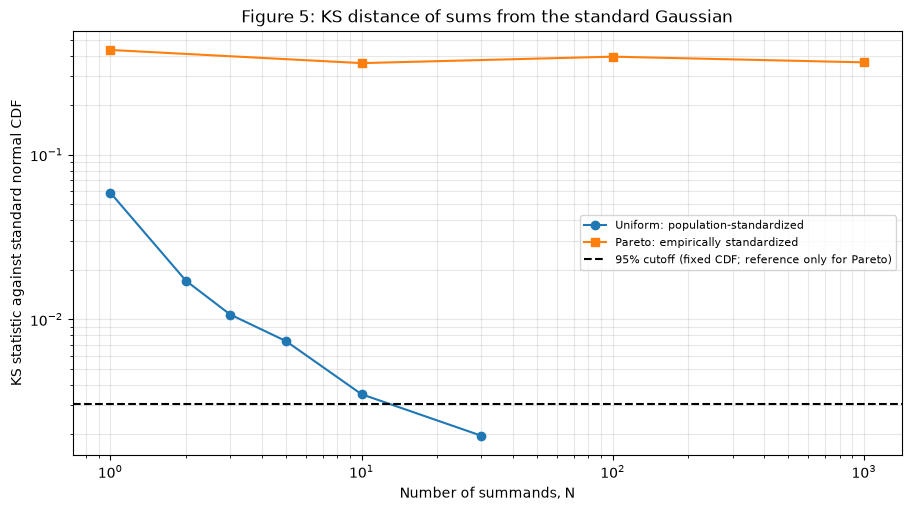

Step 5 simulation and Figure 5 time: 8.42 s


In [7]:
L5 = 200_000
uniform_N5 = np.array([1, 2, 3, 5, 10, 30])
pareto_N5 = np.array([1, 10, 100, 1000])
critical5 = 1.36 / np.sqrt(L5)

def simulate_sums5(n_summands, trials, generator, distribution, batch_size=2000):
    sums = np.empty(trials)
    for start in range(0, trials, batch_size):
        stop = min(start + batch_size, trials)
        shape = (stop - start, n_summands)
        if distribution == "uniform":
            draws = generator.random(shape)
            sums[start:stop] = draws.sum(axis=1)
        elif distribution == "pareto":
            draws = generator.pareto(1.5, size=shape)
            # Shift each summand by 1 to give Pareto scale 1.
            sums[start:stop] = draws.sum(axis=1) + n_summands
        else:
            raise ValueError("Unknown distribution")
    return sums

step5_start = __import__("time").perf_counter()
uniform_ks5 = []
uniform_examples5 = {}
print(f"Independent sums per setting: L = {L5:,}")
print(f"Fixed-CDF 95% KS cutoff = {critical5:.6f}")
print("\nUniform sums, using exact population centering and scaling:")
print(f"{'N':>6} {'KS vs normal':>15}  Decision")
for n in uniform_N5:
    sums = simulate_sums5(int(n), L5, rng_step5, "uniform")
    standardized = (sums - n/2) / np.sqrt(n/12)
    statistic = ks_statistic(standardized, stats.norm.cdf)
    uniform_ks5.append(statistic)
    if n in (1, 3, 30):
        uniform_examples5[int(n)] = standardized
    decision = "Reject at 5%" if statistic > critical5 else "Do not reject"
    print(f"{n:6d} {statistic:15.6f}  {decision}")

pareto_ks5 = []
pareto_stable_ks5 = []
print("\nPareto sums (empirical standardization is descriptive):")
print(f"{'N':>6} {'Empirical mean':>17} {'Empirical SD':>17} {'KS: empirical z':>18} {'KS: stable scaling':>20}")
for n in pareto_N5:
    sums = simulate_sums5(int(n), L5, rng_step5, "pareto")
    sample_mean = np.mean(sums)
    sample_sd = np.std(sums, ddof=1)
    standardized = (sums - sample_mean) / sample_sd
    statistic = ks_statistic(standardized, stats.norm.cdf)
    stable_scaled = (sums - 3*n) / n**(2/3)
    stable_statistic = ks_statistic(stable_scaled, stats.norm.cdf)
    pareto_ks5.append(statistic)
    pareto_stable_ks5.append(stable_statistic)
    print(f"{n:6d} {sample_mean:17.6f} {sample_sd:17.6f} {statistic:18.6f} {stable_statistic:20.6f}")

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.loglog(uniform_N5, uniform_ks5, "o-",
          label="Uniform: population-standardized")
ax.loglog(pareto_N5, pareto_ks5, "s-",
          label="Pareto: empirically standardized")
ax.axhline(critical5, color="black", linestyle="--",
           label="95% cutoff (fixed CDF; reference only for Pareto)")
ax.set(title="Figure 5: KS distance of sums from the standard Gaussian",
       xlabel="Number of summands, N", ylabel="KS statistic against standard normal CDF")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()
print(f"Step 5 simulation and Figure 5 time: {__import__('time').perf_counter()-step5_start:.2f} s")


### Interpretation of Figure 5

The uniform KS statistic decreases from 0.058846 at N = 1 to
0.001958 at N = 30, showing convergence toward a Gaussian.

The CLT describes convergence as N grows, so finite-N differences
do not contradict it. Statistical detectability depends on sample
size, while practical importance depends on the application.
For our seed, N = 30 falls below the 0.003041 cutoff, unlike the
brief’s prediction.

The Pareto KS statistics remain large (0.360–0.433) because its
infinite variance violates the classical CLT’s assumptions.
With centering 3N and scaling N^(2/3), its sums instead approach
a non-Gaussian 1.5-stable distribution; the empirically standardized
Pareto comparisons are descriptive, not calibrated 5% KS tests.

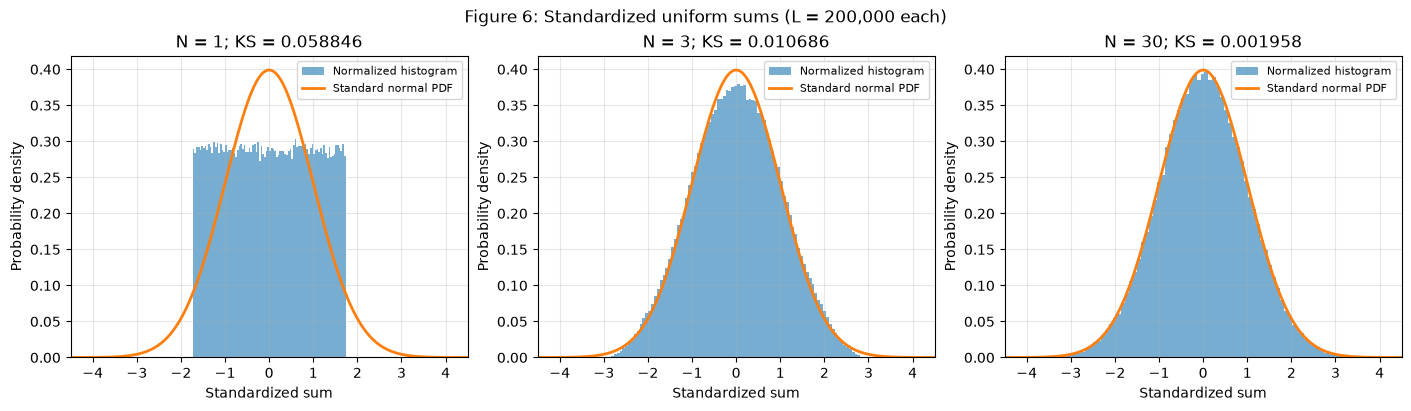

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
fig.suptitle(f"Figure 6: Standardized uniform sums (L = {L5:,} each)")
x5 = np.linspace(-4.5, 4.5, 1000)
for ax, n in zip(axes, (1, 3, 30)):
    ax.hist(uniform_examples5[n], bins=90, density=True, alpha=0.6,
            label="Normalized histogram")
    ax.plot(x5, stats.norm.pdf(x5), linewidth=2, label="Standard normal PDF")
    statistic = uniform_ks5[list(uniform_N5).index(n)]
    ax.set(title=f"N = {n}; KS = {statistic:.6f}",
           xlabel="Standardized sum", ylabel="Probability density", xlim=(-4.5, 4.5))
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
plt.show()


### Interpretation of Figure 6

At $N=1$, the standardized uniform has bounded support $[-\sqrt3,\sqrt3]$ and a flat density, which differs substantially from the bell-shaped Gaussian. At $N=3$ the sum is smoother, and at $N=30$ it is much closer to the Gaussian in its central region. The respective KS statistics are $0.058846$, $0.010686$, and $0.001958$, compared with the fixed-CDF 95% cutoff $0.003041$. These numerical comparisons quantify the changing discrepancy; normalized histogram shapes alone do not establish goodness of fit. Tail-sensitive applications may require more than a small overall KS distance because the CLT does not guarantee small relative errors for rare events.


## Step 6: A threshold detector in Gaussian noise

### Deriving false-alarm and detection probabilities
The receiver declares detection when $X>T$. Under $H_0$, $X\sim\mathcal N(0,\sigma^2)$, and under $H_1$, $X\sim\mathcal N(A,\sigma^2)$. Define
$$
Q(x)=\Pr(Z>x)=\int_x^\infty\frac{e^{-z^2/2}}{\sqrt{2\pi}}\,dz,
\qquad Z\sim\mathcal N(0,1).
$$
Under $H_0$, $X/\sigma\sim\mathcal N(0,1)$, so
$$
P_{FA}=\Pr(X>T\mid H_0)
=\Pr\left(\frac X\sigma>\frac T\sigma\mid H_0\right)
=Q(T/\sigma).
$$
Under $H_1$, $(X-A)/\sigma\sim\mathcal N(0,1)$, giving
$$
P_D=\Pr(X>T\mid H_1)
=\Pr\left(\frac{X-A}{\sigma}>\frac{T-A}{\sigma}\mid H_1\right)
=Q((T-A)/\sigma).
$$

### Accurate Q function
Substituting $z=\sqrt2\,t$ in the integral gives
$$
Q(x)=\frac1{\sqrt\pi}\int_{x/\sqrt2}^\infty e^{-t^2}\,dt
=\frac12\operatorname{erfc}(x/\sqrt2).
$$
Our `q_function` in `mp2lib.py` evaluates this complementary-error-function expression. It does not numerically integrate the density or call a Gaussian survival function. We use SciPy's Gaussian survival function only as an independent reference for validation at three arguments, including one with a tail probability of $10^{-7}$.

### Choosing the threshold
For a specified false-alarm probability,
$$
P_{FA}=Q(T/\sigma)
\ \Longrightarrow\ \frac T\sigma=Q^{-1}(P_{FA}),
\qquad P_D=Q\big(Q^{-1}(P_{FA})-A/\sigma\big).
$$
We use SciPy's inverse Gaussian survival function to compute $Q^{-1}$ accurately, avoiding subtraction of a tiny probability from one. The table uses $A/\sigma=3$ and $P_{FA}=10^{-2},10^{-3},10^{-4},10^{-6}$.

### Monte Carlo trial counts and standard errors
For $n$ independent Bernoulli trials, the true standard error of a sample proportion is $\sqrt{p(1-p)/n}$. Requiring relative standard error approximately 10% for small $p$ gives
$$
\frac{\sqrt{p(1-p)/n}}p\lesssim0.1
\ \Longrightarrow\ n\gtrsim\frac{100(1-p)}p\approx\frac{100}p.
$$
We verify the $10^{-3}$ and $10^{-4}$ rows with $10^6$ independent trials **under each hypothesis for each row**. This gives design false-alarm relative standard errors of about 3.16% and 10%, respectively. The output reports event counts, trial counts, estimates, estimated standard errors, and theory-based standard errors for both false alarms and detections. We choose $\sigma=1$ and $A=3$ without loss of generality.


Q-function validation against SciPy (reference only):
             x         q_function          Reference     Absolute error
  0.0000000000 5.000000000000e-01 5.000000000000e-01          0.000e+00
  3.0000000000 1.349898031630e-03 1.349898031630e-03          2.602e-18
  5.1993375822 1.000000000000e-07 1.000000000000e-07          3.970e-22

Gaussian detector table: A/sigma = 3
   Design P_FA        T/sigma            P_D
       1.0e-02       2.326348       0.749734
       1.0e-03       3.090232       0.464051
       1.0e-04       3.719016       0.236065
       1.0e-06       4.753424       0.039765

Monte Carlo verification (fresh samples for each hypothesis and row):
 Design P_FA   Event      Theory    Estimate     Count      Trials      Est. SE    Theory SE
     1.0e-03    P_FA    0.001000    0.001001     1,001   1,000,000    3.162e-05    3.161e-05
     1.0e-03     P_D    0.464051    0.464787   464,787   1,000,000    4.988e-04    4.987e-04
     1.0e-04    P_FA    0.000100    0.000116 

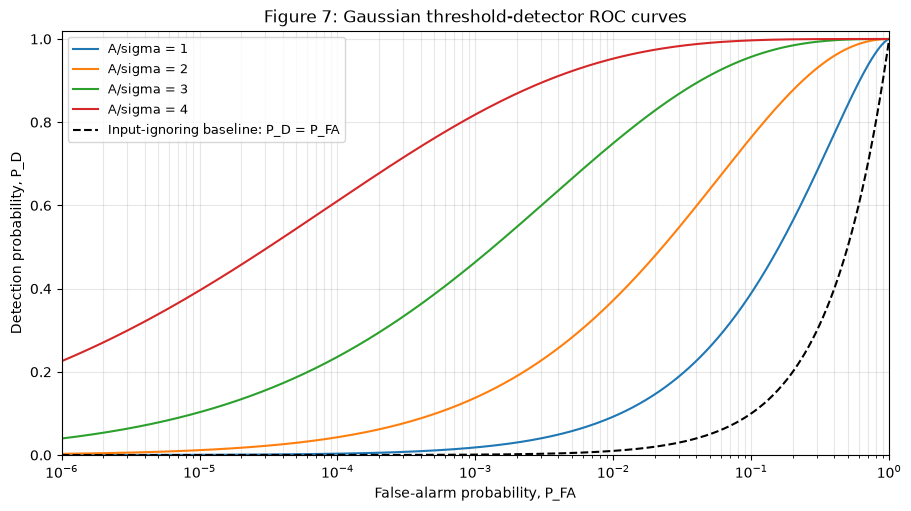

In [9]:
# Validate our erfc-based implementation, including a tail probability of 1e-7.
q_arguments6 = np.array([0.0, 3.0, stats.norm.isf(1e-7)])
q_values6 = q_function(q_arguments6)
q_reference6 = stats.norm.sf(q_arguments6)
print("Q-function validation against SciPy (reference only):")
print(f"{'x':>14} {'q_function':>18} {'Reference':>18} {'Absolute error':>18}")
for x, value, reference in zip(q_arguments6, q_values6, q_reference6):
    print(f"{x:14.10f} {value:18.12e} {reference:18.12e} {abs(value-reference):18.3e}")
np.testing.assert_allclose(q_values6, q_reference6, rtol=1e-12, atol=0)

pfa_design6 = np.array([1e-2, 1e-3, 1e-4, 1e-6])
thresholds6 = stats.norm.isf(pfa_design6)
pd_theory6 = q_function(thresholds6 - 3.0)
print("\nGaussian detector table: A/sigma = 3")
print(f"{'Design P_FA':>14} {'T/sigma':>14} {'P_D':>14}")
for pfa, threshold, pd in zip(pfa_design6, thresholds6, pd_theory6):
    print(f"{pfa:14.1e} {threshold:14.6f} {pd:14.6f}")

trials6 = 1_000_000
mc_results6 = []
print("\nMonte Carlo verification (fresh samples for each hypothesis and row):")
print(f"{'Design P_FA':>12} {'Event':>7} {'Theory':>11} {'Estimate':>11} {'Count':>9} {'Trials':>11} {'Est. SE':>12} {'Theory SE':>12}")
for pfa in (1e-3, 1e-4):
    threshold = stats.norm.isf(pfa)
    noise_only = rng_step6.normal(0.0, 1.0, trials6)
    signal_noise = rng_step6.normal(3.0, 1.0, trials6)
    for event, count, theory in [
        ("P_FA", np.count_nonzero(noise_only > threshold), pfa),
        ("P_D", np.count_nonzero(signal_noise > threshold),
         float(q_function(threshold - 3.0)))
    ]:
        estimate = count / trials6
        estimated_se = np.sqrt(estimate * (1 - estimate) / trials6)
        theory_se = np.sqrt(theory * (1 - theory) / trials6)
        mc_results6.append((pfa, event, theory, estimate, count, estimated_se, theory_se))
        print(f"{pfa:12.1e} {event:>7} {theory:11.6f} {estimate:11.6f} "
              f"{count:9,d} {trials6:11,d} {estimated_se:12.3e} {theory_se:12.3e}")

pfa_grid6 = np.geomspace(1e-6, 1.0, 700)
threshold_grid6 = stats.norm.isf(pfa_grid6)
fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
for amplitude_ratio in (1, 2, 3, 4):
    pd_grid = q_function(threshold_grid6 - amplitude_ratio)
    ax.semilogx(pfa_grid6, pd_grid, label=f"A/sigma = {amplitude_ratio}")
ax.semilogx(pfa_grid6, pfa_grid6, "k--", label="Input-ignoring baseline: P_D = P_FA")
ax.set(title="Figure 7: Gaussian threshold-detector ROC curves",
       xlabel="False-alarm probability, P_FA", ylabel="Detection probability, P_D",
       xlim=(1e-6, 1), ylim=(0, 1.02))
ax.legend(fontsize=9)
ax.grid(True, which="both", alpha=0.3)
plt.show()


### Interpretation of Figure 7

Higher $A/\sigma$ increases the probability of detection at a fixed false-alarm probability, shifting the ROC upward. Tightening the false-alarm requirement raises the threshold and reduces detection probability: at $A/\sigma=3$, $P_{FA}=10^{-3}$ gives $T/\sigma=3.090232$ and $P_D=0.464051$, while $P_{FA}=10^{-6}$ gives $T/\sigma=4.753424$ and $P_D=0.039765$. Thus even an amplitude three times the noise standard deviation does not guarantee high detection probability at a low false-alarm operating point.

For design $P_{FA}=1e-03$, the simulated $P_FA$ is $0.001001$ with estimated standard error $3.162e-05$ (1,001 events in 1,000,000 trials), a signed discrepancy of $0.03$ theory-based standard errors.

For design $P_{FA}=1e-03$, the simulated $P_D$ is $0.464787$ with estimated standard error $4.988e-04$ (464,787 events in 1,000,000 trials), a signed discrepancy of $1.48$ theory-based standard errors.

For design $P_{FA}=1e-04$, the simulated $P_FA$ is $0.000116$ with estimated standard error $1.077e-05$ (116 events in 1,000,000 trials), a signed discrepancy of $1.60$ theory-based standard errors.

For design $P_{FA}=1e-04$, the simulated $P_D$ is $0.235645$ with estimated standard error $4.244e-04$ (235,645 events in 1,000,000 trials), a signed discrepancy of $-0.99$ theory-based standard errors.

An input-ignoring detector that declares a detection with fixed probability $r$ has $P_D=P_{FA}=r$, so varying $r$ traces the diagonal in ordinary probability coordinates. On this plot's logarithmic horizontal axis, that baseline appears curved and lies below the useful detector curves for positive $A/\sigma$.
